In [1]:
import glob, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import StratifiedKFold

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)

CLASS_NAMES = ["Normal", "Not Normal", "Lung Opacity"]     # labels 0, 1, 2
LEVELS = ["Routine", "Review soon", "Urgent"]              # levels 0, 1, 2
RES = Path("/kaggle/working/triage"); RES.mkdir(parents=True, exist_ok=True)

def find(pattern):
    hits = glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)
    assert hits, f"'{pattern}' not found - attach the dataset that contains it (Add Input -> Your Datasets)"
    return hits[0]

tr = pd.read_csv(find("train.csv"))
va = pd.read_csv(find("val.csv"))
y, views = va["label"].values, va["view"].values
p_raw = np.load(find("densenet121_plain_val_probs.npy"))
assert p_raw.shape == (len(va), 3), p_raw.shape

print("val images:", len(va), "| AP:", (views == "AP").sum(), "| PA:", (views == "PA").sum())
print("macro-AUROC (must be 0.882):", round(roc_auc_score(y, p_raw, multi_class="ovr", average="macro"), 3))

PRIOR = np.bincount(tr["label"].values, minlength=3) / len(tr)     # real class frequencies in the training set
print("training class prior (Normal / Not Normal / Opacity):", PRIOR.round(3))

val images: 4003 | AP: 1867 | PA: 2136
macro-AUROC (must be 0.882): 0.882
training class prior (Normal / Not Normal / Opacity): [0.332 0.443 0.225]


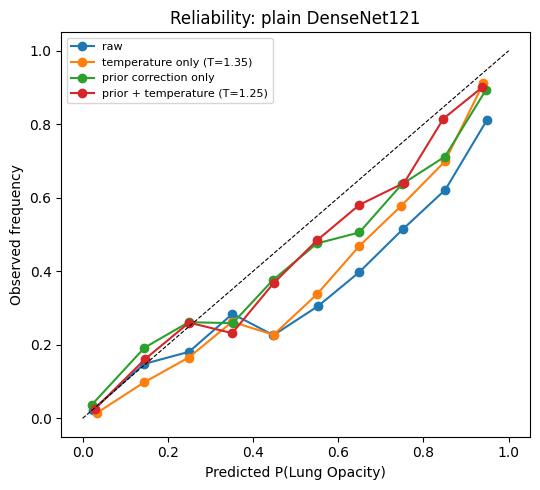

                                ECE  Brier    NLL
raw                           0.082  0.127  0.655
temperature only (T=1.35)     0.084  0.123  0.634
prior correction only         0.044  0.114  0.613
prior + temperature (T=1.25)  0.030  0.112  0.602


In [2]:
def ece_binary(prob, target, bins=10):
    """Expected calibration error: average gap between predicted and observed frequency."""
    edges, e = np.linspace(0, 1, bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if m.any(): e += m.mean() * abs(prob[m].mean() - target[m].mean())
    return e

def reliability_points(prob, target, bins=10):
    edges, xs, ys = np.linspace(0, 1, bins + 1), [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (prob >= lo) & (prob < hi if hi < 1 else prob <= hi)
        if m.sum() >= 20: xs.append(prob[m].mean()); ys.append(target[m].mean())
    return xs, ys

def prior_correct(p, prior):
    """Undo the 'all classes equally common' assumption left by class-weighted training."""
    q = p * prior
    return q / q.sum(1, keepdims=True)

def apply_temperature(p, T):
    z = np.log(np.clip(p, 1e-8, 1)) / T
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def fit_temperature(p, y):
    grid = np.arange(0.5, 3.01, 0.05)
    nll = [-np.log(apply_temperature(p, T)[np.arange(len(y)), y] + 1e-12).mean() for T in grid]
    return float(grid[int(np.argmin(nll))])

def calibrate(p, prior, T):
    """The full calibration used everywhere later: prior correction first, then temperature."""
    return apply_temperature(prior_correct(p, prior), T)

t_op = (y == 2).astype(int)
T_only = fit_temperature(p_raw, y)                       # what notebook 03 did
T_pc = fit_temperature(prior_correct(p_raw, PRIOR), y)   # temperature fitted AFTER the prior correction
P = calibrate(p_raw, PRIOR, T_pc)                        # final calibrated probabilities

variants = {"raw": p_raw,
            f"temperature only (T={T_only:.2f})": apply_temperature(p_raw, T_only),
            "prior correction only": prior_correct(p_raw, PRIOR),
            f"prior + temperature (T={T_pc:.2f})": P}

rows = {}
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, pp in variants.items():
    rows[name] = {"ECE": ece_binary(pp[:, 2], t_op),
                  "Brier": brier_score_loss(t_op, pp[:, 2]),
                  "NLL": -np.log(pp[np.arange(len(y)), y] + 1e-12).mean()}
    xs, ys = reliability_points(pp[:, 2], t_op)
    ax.plot(xs, ys, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("Predicted P(Lung Opacity)"); ax.set_ylabel("Observed frequency")
ax.set_title("Reliability: plain DenseNet121"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RES / "calibration_v2.png", dpi=150); plt.show()
print(pd.DataFrame(rows).T.round(3))

A global, 2% target          {'AP': (0.28, 0.61), 'PA': (0.28, 0.61)}
B global, 1.5% margin        {'AP': (0.28, 0.65), 'PA': (0.28, 0.65)}
C per-view, 1.5% margin      {'AP': (0.39, 0.58), 'PA': (0.12, 0.85)}
D view unknown (strictest)   {'AP': (0.12, 0.85), 'PA': (0.12, 0.85)}
                                  urgent_recall  urgent_precision  opacity_to_routine  routine_share  urgent_share
policy                     group                                                                                  
A global, 2% target        all            0.800             0.512               0.020          0.320         0.352
                           AP             0.864             0.550               0.008          0.107         0.596
                           PA             0.567             0.370               0.062          0.506         0.139
B global, 1.5% margin      all            0.800             0.512               0.013          0.299         0.352
                           AP 

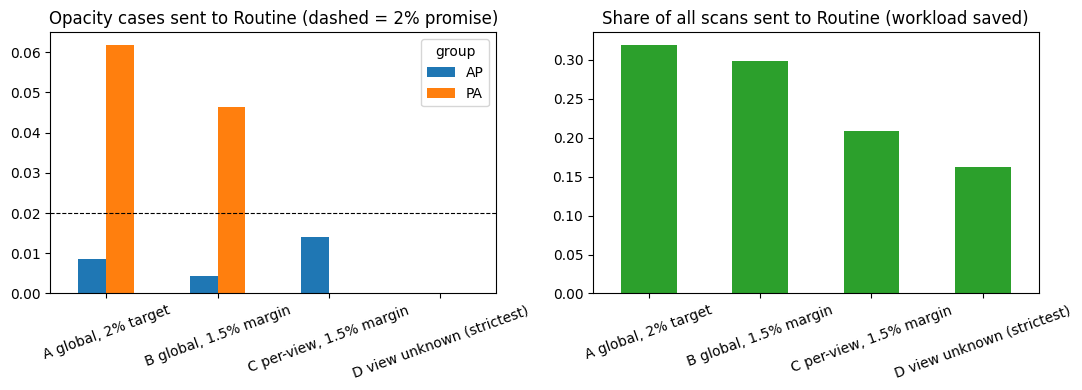

In [3]:
def assign_triage(p, t_u, t_r):
    """Urgent if P(opacity) >= t_u; else Routine if P(normal) >= t_r; else Review soon."""
    level = np.full(len(p), 1)
    level[p[:, 0] >= t_r] = 0
    level[p[:, 2] >= t_u] = 2
    return level

def triage_metrics(y, level):
    opacity, abnormal = (y == 2), (y >= 1)
    urgent, routine = (level == 2), (level == 0)
    return {"urgent_recall": urgent[opacity].mean() if opacity.any() else np.nan,
            "urgent_precision": opacity[urgent].mean() if urgent.any() else np.nan,
            "opacity_to_routine": routine[opacity].mean() if opacity.any() else np.nan,
            "abnormal_to_routine": routine[abnormal].mean() if abnormal.any() else np.nan,
            "routine_share": routine.mean(),
            "urgent_share": urgent.mean()}

TARGET_RECALL = 0.80       # flag at least 80% of opacity cases as Urgent
MAX_RISK_DEPLOY = 0.02     # the promise: at most 2% of opacity cases sent to Routine
MAX_RISK_DESIGN = 0.015    # what we tune to: a safety margin below the promise
GRID = np.round(np.arange(0.01, 1.0, 0.01), 2)

def pick_thresholds(p, y, target_recall, max_risk):
    op = (y == 2)
    t_u = max([t for t in GRID if (p[op, 2] >= t).mean() >= target_recall], default=float(GRID[0]))
    ok = [t for t in GRID if triage_metrics(y, assign_triage(p, t_u, t))["opacity_to_routine"] <= max_risk]
    return float(t_u), float(min(ok)) if ok else 1.0

def apply_policy(p, views, th):
    """th maps each view ('AP', 'PA') to its own (t_urgent, t_routine)."""
    assert set(np.unique(views)) <= set(th), "a view has no thresholds"
    level = np.empty(len(p), dtype=int)
    for v, (t_u, t_r) in th.items():
        m = views == v
        level[m] = assign_triage(p[m], t_u, t_r)
    return level

# A: one global pair of thresholds, tuned to the 2% promise itself
tA = pick_thresholds(P, y, TARGET_RECALL, MAX_RISK_DEPLOY)
# B: one global pair, tuned to 1.5% (safety margin)
tB = pick_thresholds(P, y, TARGET_RECALL, MAX_RISK_DESIGN)
# C: separate thresholds for AP and PA films, each tuned to 1.5%
tC = {v: pick_thresholds(P[views == v], y[views == v], TARGET_RECALL, MAX_RISK_DESIGN) for v in ["AP", "PA"]}
# D: view unknown (plain uploaded image): the stricter of C's two views
tD = (min(t[0] for t in tC.values()), max(t[1] for t in tC.values()))

POLICIES = {"A global, 2% target": {"AP": tA, "PA": tA},
            "B global, 1.5% margin": {"AP": tB, "PA": tB},
            "C per-view, 1.5% margin": tC,
            "D view unknown (strictest)": {"AP": tD, "PA": tD}}
for n, th in POLICIES.items():
    print(f"{n:28s}", {v: tuple(round(x, 2) for x in t) for v, t in th.items()})

GROUPS = [("all", np.ones(len(y), bool)), ("AP", views == "AP"), ("PA", views == "PA")]
KEYS = ["urgent_recall", "urgent_precision", "opacity_to_routine", "routine_share", "urgent_share"]
rows = []
for n, th in POLICIES.items():
    lvl = apply_policy(P, views, th)
    for g, m in GROUPS:
        rows.append({"policy": n, "group": g, **{k: v for k, v in triage_metrics(y[m], lvl[m]).items() if k in KEYS}})
cmp_df = pd.DataFrame(rows).set_index(["policy", "group"])
print(cmp_df.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
risk = cmp_df["opacity_to_routine"].unstack("group")[["AP", "PA"]]
risk.plot.bar(ax=ax[0], rot=20); ax[0].axhline(MAX_RISK_DEPLOY, color="k", ls="--", lw=0.8)
ax[0].set_title("Opacity cases sent to Routine (dashed = 2% promise)"); ax[0].set_xlabel("")
save = cmp_df["routine_share"].unstack("group")[["all"]]
save.plot.bar(ax=ax[1], rot=20, legend=False, color="tab:green")
ax[1].set_title("Share of all scans sent to Routine (workload saved)"); ax[1].set_xlabel("")
fig.tight_layout(); fig.savefig(RES / "policy_comparison.png", dpi=150); plt.show()

In [4]:
rng = np.random.default_rng(42)
lvlC = apply_policy(P, views, tC)
KEYS2 = ["urgent_recall", "opacity_to_routine", "routine_share"]
boot = {(g, k): [] for g, _ in GROUPS for k in KEYS2}
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    yy, vv, ll = y[i], views[i], lvlC[i]
    for g, _m in GROUPS:
        m = np.ones(len(yy), bool) if g == "all" else (vv == g)
        mt = triage_metrics(yy[m], ll[m])
        for k in KEYS2: boot[(g, k)].append(mt[k])

print("Policy C (per-view, 1.5% margin), 95% bootstrap intervals on validation data")
for g, m in GROUPS:
    pt = triage_metrics(y[m], lvlC[m])
    for k in KEYS2:
        lo, hi = np.nanpercentile(boot[(g, k)], [2.5, 97.5])
        print(f"  {g:3s} {k:20s} {pt[k]:.3f}   (95% CI {lo:.3f} - {hi:.3f})")

Policy C (per-view, 1.5% margin), 95% bootstrap intervals on validation data
  all urgent_recall        0.805   (95% CI 0.779 - 0.831)
  all opacity_to_routine   0.011   (95% CI 0.005 - 0.019)
  all routine_share        0.208   (95% CI 0.196 - 0.221)
  AP  urgent_recall        0.801   (95% CI 0.771 - 0.830)
  AP  opacity_to_routine   0.014   (95% CI 0.006 - 0.024)
  AP  routine_share        0.119   (95% CI 0.105 - 0.135)
  PA  urgent_recall        0.820   (95% CI 0.759 - 0.867)
  PA  opacity_to_routine   0.000   (95% CI 0.000 - 0.000)
  PA  routine_share        0.286   (95% CI 0.267 - 0.305)


In [5]:
strat = (pd.Series(y).astype(str) + "_" + pd.Series(views)).values
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def out_of_fold_levels(per_view):
    """Pick thresholds on 4 folds, apply them to the 5th; repeat, so every scan is judged by thresholds that never saw it."""
    lvl = np.empty(len(y), dtype=int)
    for a, b in skf.split(P, strat):
        if per_view:
            th = {v: pick_thresholds(P[a][views[a] == v], y[a][views[a] == v], TARGET_RECALL, MAX_RISK_DESIGN)
                  for v in ["AP", "PA"]}
        else:
            t = pick_thresholds(P[a], y[a], TARGET_RECALL, MAX_RISK_DESIGN)
            th = {"AP": t, "PA": t}
        lvl[b] = apply_policy(P[b], views[b], th)
    return lvl

out = []
for name, per_view, th in [("B global, 1.5% margin", False, POLICIES["B global, 1.5% margin"]),
                           ("C per-view, 1.5% margin", True, tC)]:
    lvl_in, lvl_oof = apply_policy(P, views, th), out_of_fold_levels(per_view)
    for g, m in GROUPS:
        a, b = triage_metrics(y[m], lvl_in[m]), triage_metrics(y[m], lvl_oof[m])
        out.append({"policy": name, "group": g,
                    "opacity_to_routine (tuned on this data)": a["opacity_to_routine"],
                    "opacity_to_routine (out-of-fold)": b["opacity_to_routine"],
                    "urgent_recall (out-of-fold)": b["urgent_recall"],
                    "routine_share (out-of-fold)": b["routine_share"]})
print(pd.DataFrame(out).set_index(["policy", "group"]).round(3))

                               opacity_to_routine (tuned on this data)  opacity_to_routine (out-of-fold)  urgent_recall (out-of-fold)  routine_share (out-of-fold)
policy                  group                                                                                                                                     
B global, 1.5% margin   all                                      0.013                             0.014                        0.799                        0.298
                        AP                                       0.004                             0.006                        0.859                        0.092
                        PA                                       0.046                             0.046                        0.582                        0.478
C per-view, 1.5% margin all                                      0.011                             0.018                        0.805                        0.225
                      

In [6]:
def clean(t): return {"t_urgent": round(float(t[0]), 2), "t_routine": round(float(t[1]), 2)}

config = {
    "model": "densenet121_plain",
    "calibration": {"step_1": "multiply class probabilities by the training class prior, renormalise",
                    "prior_normal_notnormal_opacity": [round(float(x), 4) for x in PRIOR],
                    "step_2": "temperature scaling (divide log-probabilities by T, renormalise)",
                    "temperature": round(T_pc, 2)},
    "policy": "Urgent if P(opacity) >= t_urgent; else Routine if P(normal) >= t_routine; else Review soon",
    "targets": {"urgent_recall": TARGET_RECALL, "promise_max_opacity_to_routine": MAX_RISK_DEPLOY,
                "design_max_opacity_to_routine": MAX_RISK_DESIGN},
    "thresholds_when_view_known": {v: clean(t) for v, t in tC.items()},
    "thresholds_when_view_unknown": clean(tD),
    "selected_on": "validation set only; test set untouched"}

json.dump(config, open(RES / "triage_config_v2.json", "w"), indent=2)
np.save(RES / "plain_val_probs_calibrated.npy", P)
cmp_df.to_csv(RES / "policy_comparison.csv")
print(json.dumps(config, indent=2))

{
  "model": "densenet121_plain",
  "calibration": {
    "step_1": "multiply class probabilities by the training class prior, renormalise",
    "prior_normal_notnormal_opacity": [
      0.3317,
      0.443,
      0.2253
    ],
    "step_2": "temperature scaling (divide log-probabilities by T, renormalise)",
    "temperature": 1.25
  },
  "policy": "Urgent if P(opacity) >= t_urgent; else Routine if P(normal) >= t_routine; else Review soon",
  "targets": {
    "urgent_recall": 0.8,
    "promise_max_opacity_to_routine": 0.02,
    "design_max_opacity_to_routine": 0.015
  },
  "thresholds_when_view_known": {
    "AP": {
      "t_urgent": 0.39,
      "t_routine": 0.58
    },
    "PA": {
      "t_urgent": 0.12,
      "t_routine": 0.85
    }
  },
  "thresholds_when_view_unknown": {
    "t_urgent": 0.12,
    "t_routine": 0.85
  },
  "selected_on": "validation set only; test set untouched"
}
